# Baselines: raw NWP, persistence and persistence ensemble (PeEn)

**Setup**
- Samples are identical to Table 2: the validation targets $y_t$ of each location, indexed as in `anen_metrics.py` / `a2e_metrics.py`.
- Issue time is $t-2$; the most recent known observation is $y_{t-2}$.
- Baselines:
  - Raw NWP: point forecast $x_t$.
  - Persistence: point forecast $y_{t-2}$.
  - PeEn($k$): equally weighted ensemble of $y_{t-2}, \dots, y_{t-k-1}$.
- Metrics: Bias, CRPS and SCRPS use `a2e.metrics.computation` as in Table 2. RMSE is the RMSE of the ensemble mean (paper equation).
- For point forecasts the CRPS equals the MAE. The SCRPS is not defined for point forecasts ($E|X-X'| = 0$).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[2]))  # repository root

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import a2e
from experiments.data import WindDataLoader
from experiments.project_paths import METRICS_EVALUATION_CSV, OBSERVATIONS_WIND_SPEED_CSV

loader = WindDataLoader()
observations, forecasts = loader.get_all_data(obs_components=["total"], fcst_components=["total"])
obs, fcst = observations[..., 0].astype(np.float32), forecasts[..., 0].astype(np.float32)
dates = pd.read_csv(OBSERVATIONS_WIND_SPEED_CSV, usecols=[0], index_col=0, parse_dates=True).index
T, n_loc = obs.shape

FORESIGHT, TIME_TO_TARGET = 1, 2
test_size = int((T - 8760 * 2) * 0.3) - 2
tau_val = np.arange(T - test_size - FORESIGHT, T - FORESIGHT)   # validation targets (Table 2)
tau_train = np.arange(8760 * 2, tau_val[0])                       # training targets, used to select k

# Same samples as the evaluation scripts (shifted arrays)
idx = FORESIGHT + TIME_TO_TARGET
assert np.array_equal(obs[idx:][-test_size - FORESIGHT:-FORESIGHT], obs[tau_val])

print(f"Training targets:   {dates[tau_train[0]]} … {dates[tau_train[-1]]}  ({len(tau_train)} per location)")
print(f"Validation targets: {dates[tau_val[0]]} … {dates[tau_val[-1]]}  ({len(tau_val)} per location)")

Training targets:   2024-01-01 00:00:00+00:00 … 2024-12-27 22:00:00+00:00  (8687 per location)
Validation targets: 2024-12-27 23:00:00+00:00 … 2025-05-31 22:00:00+00:00  (3720 per location)


In [2]:
def scores(ens, y, point):
    """Bias, RMSE (ensemble mean), CRPS and SCRPS of an equally weighted ensemble, averaged over samples."""
    x = tf.constant(ens, tf.float32)
    w = tf.ones_like(x) / x.shape[1]
    yt = tf.constant(y, tf.float32)
    bias = a2e.metrics.computation.compute_bias(x, w, yt).numpy().ravel()
    out = dict(Bias=bias.mean(), RMSE=np.sqrt(np.mean(bias ** 2)),
               CRPS=(-a2e.metrics.computation.compute_crps(x, w, yt)).numpy().mean(), SCRPS=np.nan)
    if not point:
        out["SCRPS"] = (-a2e.metrics.computation.compute_scrps(x, w, yt)).numpy().mean()
    return out

def peen(series, tau, k):
    """PeEn members y_{t-2}, ..., y_{t-k-1}; shape (samples, k)."""
    return np.stack([series[tau - TIME_TO_TARGET - j] for j in range(k)], axis=1)

## PeEn: choice of $k$

$k$ is selected by the mean CRPS over all 82 locations on the training targets. The validation CRPS is shown for reference and is not used for the selection. `zero spread` is the share of validation samples whose members are all identical; for these samples $E|X-X'| = 0$ and the SCRPS is unbounded.

In [3]:
K_GRID = [1, 2, 3, 4, 6, 8, 12, 16, 24, 36, 48]
rows = []
for k in K_GRID:
    tr = np.mean([scores(peen(obs[:, l], tau_train, k), obs[tau_train, l], point=(k == 1))["CRPS"] for l in range(n_loc)])
    va = np.mean([scores(peen(obs[:, l], tau_val, k), obs[tau_val, l], point=(k == 1))["CRPS"] for l in range(n_loc)])
    m = np.concatenate([peen(obs[:, l], tau_val, k) for l in range(n_loc)])
    rows.append(dict(k=k, CRPS_train=tr, CRPS_validation=va, zero_spread=np.mean(m.max(1) == m.min(1)) if k > 1 else np.nan))
k_table = pd.DataFrame(rows).set_index("k")
k_best = int(k_table["CRPS_train"].idxmin())
print(f"Selected k = {k_best}")
k_table.assign(zero_spread=(100 * k_table["zero_spread"]).round(2)).rename(columns={"zero_spread": "zero_spread_%"}).round(4)

Selected k = 2


,CRPS_train,CRPS_validation,zero_spread_%
k,,,
1,0.6055,0.5618,NaN
2,0.5749,0.5410,0.54
3,0.5821,0.5501,0.01
4,0.5981,0.5663,0.00
6,0.6351,0.6029,0.00
8,0.6695,0.6371,0.00
12,0.7230,0.6900,0.00
16,0.7575,0.7234,0.00
24,0.7855,0.7511,0.00


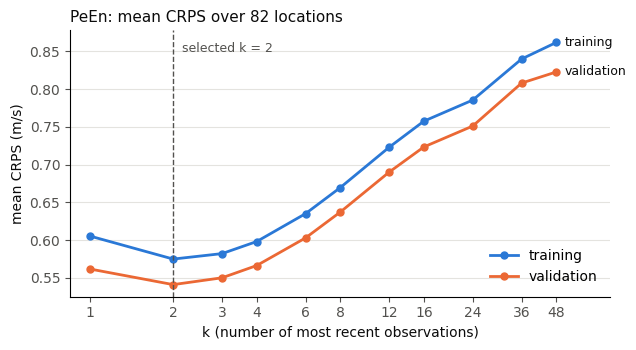

In [4]:
C_TRAIN, C_VAL, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for col, color, label in [("CRPS_train", C_TRAIN, "training"), ("CRPS_validation", C_VAL, "validation")]:
    ax.plot(k_table.index, k_table[col], color=color, lw=2, marker="o", ms=5, label=label)
    ax.annotate(label, (k_table.index[-1], k_table[col].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK, fontsize=9)
ax.axvline(k_best, color=MUTED, lw=1, ls="--")
ax.annotate(f"selected k = {k_best}", (k_best, k_table["CRPS_train"].max()), xytext=(6, 0),
            textcoords="offset points", color=MUTED, fontsize=9, va="top")
ax.set_xscale("log", base=2)
ax.set_xticks(K_GRID, [str(k) for k in K_GRID])
ax.set_xlim(0.85, 75)
ax.set_xlabel("k (number of most recent observations)", color=INK)
ax.set_ylabel("mean CRPS (m/s)", color=INK)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.legend(frameon=False, loc="lower right")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.tick_params(colors=MUTED)
ax.set_title("PeEn: mean CRPS over 82 locations", color=INK, fontsize=11, loc="left")
plt.tight_layout()
plt.show()

## Baselines on the validation period (Table 2 samples)

In [5]:
rows = []
for l in range(n_loc):
    y = obs[tau_val, l]
    for name, ens, point in [("Raw NWP", fcst[tau_val, l][:, None], True),
                             ("Persistence", obs[tau_val - TIME_TO_TARGET, l][:, None], True),
                             (f"PeEn (k={k_best})", peen(obs[:, l], tau_val, k_best), False)]:
        rows.append(dict(location=l, model=name, **scores(ens, y, point)))
per_location = pd.DataFrame(rows)
baselines = per_location.groupby("model", sort=False)[["Bias", "RMSE", "CRPS", "SCRPS"]].mean()
baselines.loc[f"PeEn (k={k_best})", "SCRPS"] = np.nan   # unbounded due to zero-spread samples, see above
baselines.round(4)

,Bias,RMSE,CRPS,SCRPS
model,,,,
Raw NWP,-0.2762,0.9901,0.7752,NaN
Persistence,-0.0004,0.7635,0.5618,NaN
PeEn (k=2),-0.0005,0.8185,0.5410,NaN


## Comparison with the models in Table 2

CRPS skill score $\mathrm{CRPSS} = 1 - \mathrm{CRPS}/\mathrm{CRPS}_\mathrm{ref}$, computed from the means over 82 locations. Model values are taken from `metrics_evaluation.csv` (Table 2).

In [ ]:
table2 = pd.read_csv(METRICS_EVALUATION_CSV, index_col=0, header=[0, 1])
models = table2["CRPS"].mean()
crps = pd.concat([baselines["CRPS"], models])
refs = ["Raw NWP", "Persistence", f"PeEn (k={k_best})", "AnEn"]
skill = pd.DataFrame({f"CRPSS vs {r}": 1 - crps / crps[r] for r in refs})
pd.concat([crps.rename("CRPS"), skill], axis=1).round(3)